# CNN-LSTM Autoencoder Anomaly Scoring

* Generated CNN-LSTM anomaly scores for all 10 splits.
* Used the 95th percentile of normal training scores as the threshold.
* Compared CNN-LSTM-AE with the LSTM-AE baseline.
* CNN-LSTM-AE performed better across all test splits.
* Saved the anomaly scores for energy prediction models.


In [ ]:

import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path
from sklearn.metrics import roc_auc_score, average_precision_score
import gc
import warnings
warnings.filterwarnings("ignore")

BASE_DIR        = Path("/Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project")
FOLDER_VERSION  = "v3_voltage_random10_issue_flight-removed"
FILE_VERSION    = "v4_voltage_random10_cleaned"
DATA_DIR        = BASE_DIR / f"model_ready_no_dr_{FOLDER_VERSION}"

#CNN-LSTM-AE checkpoint from 05e
CHECKPOINT_DIR  = BASE_DIR / "model_outputs" / \
                  f"architecture_comparison_{FOLDER_VERSION}"
CNN_CKPT        = CHECKPOINT_DIR / "best_cnn_lstm_ae.pt"

#Original LSTM-AE scored outputs from 05c
LSTM_AE_DIR     = BASE_DIR / "model_outputs" / \
                  "lstm_autoencoder_v3_voltage_random10_interpolated_old_complex_logic"

#Output for CNN-LSTM-AE scores
OUTPUT_DIR      = BASE_DIR / "model_outputs" / f"cnn_lstm_ae_anomaly_score_{FOLDER_VERSION}"
PLOT_DIR        = OUTPUT_DIR / "plots"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

SPLIT_SEEDS = [11, 22, 33, 44, 55, 66, 77, 88, 99, 111]
ALL_SPLITS  = [f"split_{str(i+1).zfill(2)}_seed_{s}"
               for i, s in enumerate(SPLIT_SEEDS)]

device = torch.device(
    "mps"  if torch.backends.mps.is_available() else
    "cuda" if torch.cuda.is_available()          else
    "cpu"
)

print(f"Device     : {device}")
print(f"Checkpoint : {CNN_CKPT}")
print(f"Exists     : {CNN_CKPT.exists()}")
print(f"Output     : {OUTPUT_DIR}")

Device     : mps
Checkpoint : /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/architecture_comparison_v3_voltage_random10_issue_flight-removed/best_cnn_lstm_ae.pt
Exists     : True
Output     : /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/cnn_lstm_ae_anomaly_score_v3_voltage_random10_issue_flight-removed


In [4]:
FEATURE_COLS = [
    "battery_status__cell_count",
    "battery_status__current_a",
    "battery_status__current_filtered_a",
    "battery_status__discharged_mah",
    "battery_status__remaining",
    "battery_status__scale",
    "battery_status__voltage_filtered_v",
    "battery_status__voltage_v",
    "cumulative_energy_wh",
    "power_w",
    "time_s",
    "voltage_per_cell",
    "voltage_filtered_per_cell",
]

SEQ_LEN    = 100    # 10 seconds at 10 Hz — same as 05c
STRIDE     = 10     # scoring stride
BATCH_SIZE = 64
N_FEATURES = len(FEATURE_COLS)

print(f"Features  : {N_FEATURES}")
print(f"Seq length: {SEQ_LEN} rows = {SEQ_LEN/10:.0f}s")

Features  : 13
Seq length: 100 rows = 10s


In [5]:
class CNNLSTMAutoencoder(nn.Module):
    def __init__(self, input_size, cnn_channels=32,
                 lstm_hidden=64, latent_size=32):
        super().__init__()
        self.cnn_encoder = nn.Sequential(
            nn.Conv1d(input_size, cnn_channels, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv1d(cnn_channels, cnn_channels, kernel_size=3, padding=1),
            nn.ReLU(),
        )
        self.lstm_encoder = nn.LSTM(cnn_channels, lstm_hidden, batch_first=True)
        self.latent_fc    = nn.Linear(lstm_hidden, latent_size)
        self.decode_fc    = nn.Linear(latent_size, lstm_hidden)
        self.lstm_decoder = nn.LSTM(lstm_hidden, lstm_hidden, batch_first=True)
        self.output_layer = nn.Linear(lstm_hidden, input_size)

    def forward(self, x):
        cnn_out    = self.cnn_encoder(x.transpose(1, 2)).transpose(1, 2)
        _, (h, _)  = self.lstm_encoder(cnn_out)
        latent     = self.latent_fc(h[-1])
        dec_in     = self.decode_fc(latent).unsqueeze(1).repeat(1, x.size(1), 1)
        dec_out, _ = self.lstm_decoder(dec_in)
        return self.output_layer(dec_out)

# Load checkpoint
model = CNNLSTMAutoencoder(input_size=N_FEATURES).to(device)
model.load_state_dict(
    torch.load(CNN_CKPT, map_location=device, weights_only=True)
)
model.eval()
print(f"CNN-LSTM-AE loaded. Parameters: "
      f"{sum(p.numel() for p in model.parameters()):,}")

CNN-LSTM-AE loaded. Parameters: 67,789


In [6]:
class ScoreDataset(torch.utils.data.Dataset):
    def __init__(self, arr, starts, seq_len):
        self.arr, self.starts, self.seq_len = arr, starts, seq_len
    def __len__(self): return len(self.starts)
    def __getitem__(self, i):
        s = self.starts[i]
        return torch.tensor(self.arr[s:s+self.seq_len], dtype=torch.float32), s


def build_starts(df, seq_len, stride):
    starts = []
    for _, group in df.sort_values(["log_id","time_s"]).groupby("log_id"):
        idxs = group.index.to_numpy()
        if len(idxs) < seq_len:
            continue
        for offset in range(0, len(idxs) - seq_len + 1, stride):
            starts.append(idxs[offset])
    return np.array(starts, dtype=np.int64)


def score_dataframe(df, model, feature_cols, seq_len, stride, batch_size):
    df_sorted = df.sort_values(["log_id","time_s"]).reset_index(drop=True)
    X         = df_sorted[feature_cols].to_numpy(dtype=np.float32)
    starts    = build_starts(df_sorted, seq_len, stride)

    score_sum   = np.zeros(len(df_sorted), dtype=np.float64)
    score_count = np.zeros(len(df_sorted), dtype=np.float64)

    loader = torch.utils.data.DataLoader(
        ScoreDataset(X, starts, seq_len),
        batch_size=batch_size, shuffle=False
    )

    model.eval()
    with torch.no_grad():
        for batch_x, batch_starts in loader:
            batch_x = batch_x.to(device)
            recon   = model(batch_x)
            step_err = ((batch_x - recon) ** 2).mean(dim=2).cpu().numpy()
            for i, s in enumerate(batch_starts.numpy()):
                score_sum[s:s+seq_len]   += step_err[i]
                score_count[s:s+seq_len] += 1

    scores = np.where(score_count > 0, score_sum / score_count, np.nan)
    df_sorted["anomaly_score_cnn"] = scores

    # Fill within flights
    if df_sorted["anomaly_score_cnn"].isna().any():
        df_sorted["anomaly_score_cnn"] = (
            df_sorted.groupby("log_id")["anomaly_score_cnn"]
            .transform(lambda s: s.ffill().bfill())
        )
    fallback = df_sorted.loc[
        df_sorted["dataset_label"]=="normal", "anomaly_score_cnn"
    ].median()
    df_sorted["anomaly_score_cnn"] = df_sorted["anomaly_score_cnn"].fillna(fallback)

    return df_sorted


def get_flight_metrics(scored_df, score_col):
    flight = (
        scored_df.groupby(["log_id","dataset_label"])[score_col]
        .mean().reset_index().rename(columns={score_col:"mean_score"})
    )
    flight["binary"] = (flight["dataset_label"]=="abnormal").astype(int)
    if flight["binary"].nunique() < 2:
        return {"auroc": np.nan, "auprc": np.nan, "sep_ratio": np.nan}
    auroc = roc_auc_score(flight["binary"], flight["mean_score"])
    auprc = average_precision_score(flight["binary"], flight["mean_score"])
    nm = flight.loc[flight["binary"]==0,"mean_score"].mean()
    ab = flight.loc[flight["binary"]==1,"mean_score"].mean()
    return {
        "auroc":     round(float(auroc), 4),
        "auprc":     round(float(auprc), 4),
        "sep_ratio": round(float(ab/nm),  4) if nm > 0 else np.nan,
    }

print("Scoring utilities defined ✓")

Scoring utilities defined ✓


In [7]:
cnn_results   = []
lstm_results  = []   # load from 05c saved files

for split_name in ALL_SPLITS:
    print(f"\nProcessing: {split_name}")

    split_data_dir = DATA_DIR / split_name

    # Load cleaned scaled data
    test_path = split_data_dir / \
        f"test_no_dr_scaled_{FILE_VERSION}_{split_name}.parquet"
    if not test_path.exists():
        print(f"  MISSING: {test_path.name}")
        continue
    test_df = pd.read_parquet(test_path)

    # ── Score with CNN-LSTM-AE ─────────────────────────────────
    test_scored_cnn = score_dataframe(
        test_df, model, FEATURE_COLS, SEQ_LEN, STRIDE, BATCH_SIZE
    )

    # Threshold from training normal rows
    train_path = split_data_dir / \
        f"train_no_dr_scaled_{FILE_VERSION}_{split_name}.parquet"
    train_df = pd.read_parquet(train_path)
    train_scored_cnn = score_dataframe(
        train_df, model, FEATURE_COLS, SEQ_LEN, STRIDE, BATCH_SIZE
    )
    threshold_cnn = float(np.percentile(
        train_scored_cnn.loc[
            train_scored_cnn["dataset_label"]=="normal",
            "anomaly_score_cnn"
        ], 95
    ))
    test_scored_cnn["anomaly_flag_cnn"] = (
        test_scored_cnn["anomaly_score_cnn"] > threshold_cnn
    ).astype(int)

    # Save scored test file
    out_path = OUTPUT_DIR / split_name
    out_path.mkdir(parents=True, exist_ok=True)
    test_scored_cnn.to_parquet(
        out_path / f"test_cnn_lstm_ae_scored_{split_name}.parquet",
        index=False
    )

    # CNN metrics
    cnn_m = get_flight_metrics(test_scored_cnn, "anomaly_score_cnn")
    cnn_m["split"]     = split_name
    cnn_m["threshold"] = round(threshold_cnn, 6)
    flagged_abn = test_scored_cnn[
        test_scored_cnn["dataset_label"]=="abnormal"
    ]["anomaly_flag_cnn"].mean() * 100
    flagged_nor = test_scored_cnn[
        test_scored_cnn["dataset_label"]=="normal"
    ]["anomaly_flag_cnn"].mean() * 100
    cnn_m["flagged_pct_abn"] = round(float(flagged_abn), 2)
    cnn_m["flagged_pct_nor"] = round(float(flagged_nor), 2)
    cnn_results.append(cnn_m)

    # ── Load original LSTM-AE scores from 05c ──────────────────
    lstm_test_path = (LSTM_AE_DIR / split_name /
        f"test_no_dr_with_lstm_anomaly_score"
        f"_v3_voltage_random10_interpolated_{split_name}.csv")
    if lstm_test_path.exists():
        lstm_df  = pd.read_csv(lstm_test_path)
        lstm_m   = get_flight_metrics(lstm_df, "anomaly_score")
        lstm_m["split"] = split_name
        fl_abn = lstm_df[
            lstm_df["dataset_label"]=="abnormal"
        ]["anomaly_flag"].mean() * 100
        fl_nor = lstm_df[
            lstm_df["dataset_label"]=="normal"
        ]["anomaly_flag"].mean() * 100
        lstm_m["flagged_pct_abn"] = round(float(fl_abn), 2)
        lstm_m["flagged_pct_nor"] = round(float(fl_nor), 2)
        lstm_results.append(lstm_m)
    else:
        print(f"  LSTM-AE scored file not found: {lstm_test_path.name}")

    gc.collect()
    if device.type == "mps":  torch.mps.empty_cache()

cnn_df  = pd.DataFrame(cnn_results).sort_values("auroc", ascending=False)
lstm_df_summary = pd.DataFrame(lstm_results).sort_values("auroc", ascending=False)

print("\n✓ All splits scored.")
print(f"\nCNN-LSTM-AE mean AUROC : {cnn_df['auroc'].mean():.4f} ± "
      f"{cnn_df['auroc'].std():.4f}")
print(f"LSTM-AE mean AUROC    : {lstm_df_summary['auroc'].mean():.4f} ± "
      f"{lstm_df_summary['auroc'].std():.4f}")


Processing: split_01_seed_11

Processing: split_02_seed_22

Processing: split_03_seed_33

Processing: split_04_seed_44

Processing: split_05_seed_55

Processing: split_06_seed_66

Processing: split_07_seed_77

Processing: split_08_seed_88

Processing: split_09_seed_99

Processing: split_10_seed_111

✓ All splits scored.

CNN-LSTM-AE mean AUROC : 0.6376 ± 0.0868
LSTM-AE mean AUROC    : 0.5218 ± 0.1068


In [8]:

compare = cnn_df[["split","auroc","sep_ratio","flagged_pct_abn","flagged_pct_nor"]].copy()
compare.columns = ["split","CNN_auroc","CNN_sep","CNN_flag_abn","CNN_flag_nor"]

lstm_compare = lstm_df_summary[
    ["split","auroc","sep_ratio","flagged_pct_abn","flagged_pct_nor"]
].copy()
lstm_compare.columns = ["split","LSTM_auroc","LSTM_sep","LSTM_flag_abn","LSTM_flag_nor"]

merged = compare.merge(lstm_compare, on="split")
merged["AUROC_improvement"] = (
    merged["CNN_auroc"] - merged["LSTM_auroc"]
).round(4)
merged = merged.sort_values("CNN_auroc", ascending=False).reset_index(drop=True)
merged.index += 1

print("=" * 90)
print("CNN-LSTM-AE vs LSTM-AE — Anomaly Score Comparison Across 10 Splits")
print("=" * 90)
display(merged)
print(f"\nMean AUROC improvement: {merged['AUROC_improvement'].mean():+.4f}")
print(f"Splits where CNN-LSTM-AE wins: "
      f"{(merged['AUROC_improvement']>0).sum()} / {len(merged)}")

# Save
merged.to_csv(OUTPUT_DIR / "cnn_vs_lstm_comparison.csv", index=False)

CNN-LSTM-AE vs LSTM-AE — Anomaly Score Comparison Across 10 Splits


,split,CNN_auroc,CNN_sep,CNN_flag_abn,CNN_flag_nor,LSTM_auroc,LSTM_sep,LSTM_flag_abn,LSTM_flag_nor,AUROC_improvement
1,split_07_seed_77,0.7669,7.5617,17.40,0.85,0.6316,0.3379,0.03,1.24,0.1353
2,split_08_seed_88,0.7368,25.5180,40.57,6.50,0.5940,46.7694,45.05,7.84,0.1428
3,split_03_seed_33,0.6917,0.3195,0.02,15.87,0.4662,0.0466,0.00,14.94,0.2255
4,split_05_seed_55,0.6917,14.0933,21.01,0.36,0.6692,9.4109,17.01,3.27,0.0225
5,split_09_seed_99,0.6617,1.9433,0.06,0.03,0.5489,25.0694,30.24,0.63,0.1128
6,split_04_seed_44,0.6090,0.7420,0.02,0.20,0.5489,3.5860,19.54,0.86,0.0601
7,split_06_seed_66,0.6015,63.1623,44.68,2.66,0.5489,30.3243,34.57,7.59,0.0526
8,split_01_seed_11,0.5789,5.6737,21.98,0.32,0.4962,0.8599,0.00,3.50,0.0827
9,split_10_seed_111,0.5414,1.4138,0.02,1.37,0.3158,0.6007,0.01,1.36,0.2256
10,split_02_seed_22,0.4962,0.3043,0.02,1.90,0.3985,0.1803,0.00,2.46,0.0977



Mean AUROC improvement: +0.1158
Splits where CNN-LSTM-AE wins: 10 / 10


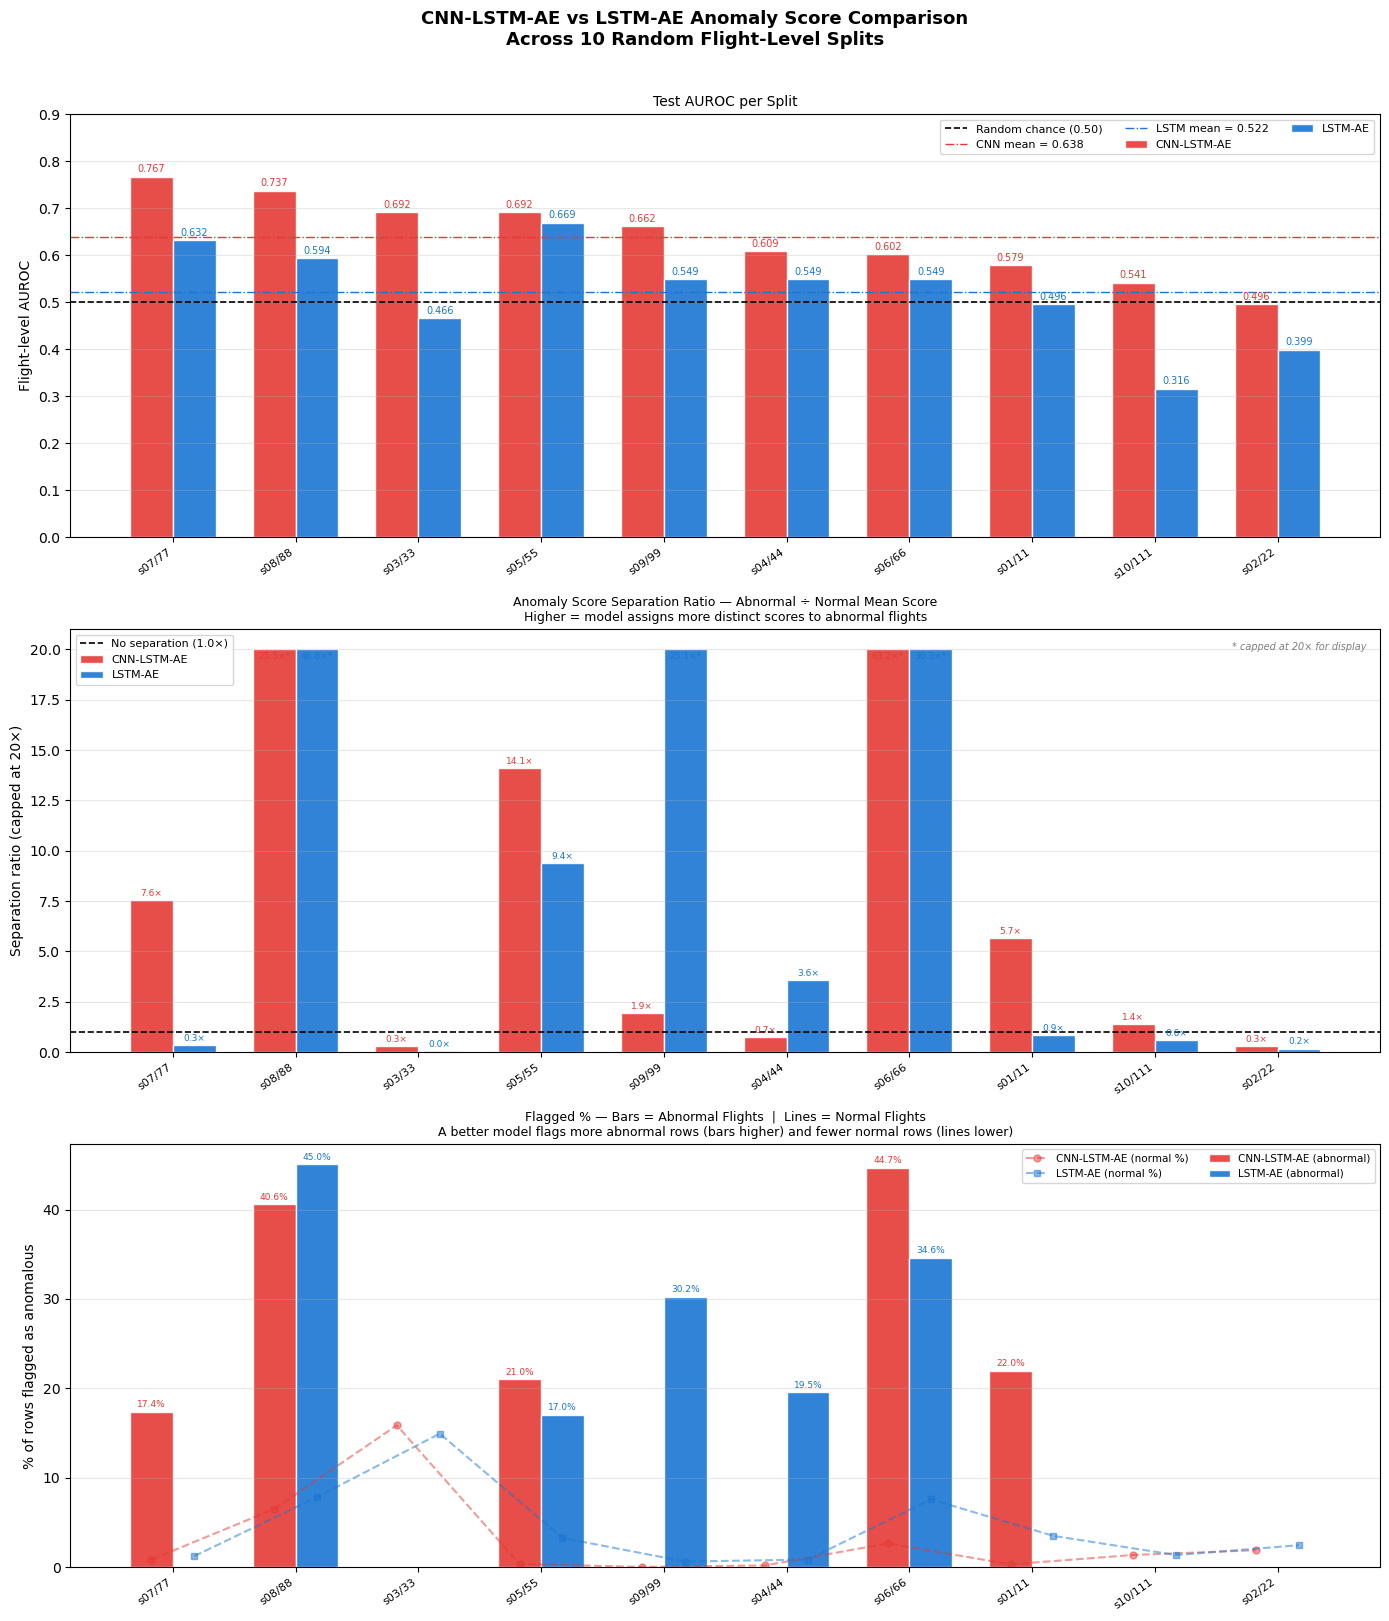

Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/cnn_lstm_ae_anomaly_score_v3_voltage_random10_issue_flight-removed/plots/cnn_vs_lstm_comparison.png


In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(14, 16))
fig.suptitle(
    "CNN-LSTM-AE vs LSTM-AE Anomaly Score Comparison\nAcross 10 Random Flight-Level Splits",
    fontsize=13, fontweight="bold", y=1.01
)

# Sort splits by CNN AUROC for consistent display order
merged_sorted = merged.sort_values("CNN_auroc", ascending=False).reset_index(drop=True)
splits_short  = [s.replace("split_","s").replace("_seed_","/")
                 for s in merged_sorted["split"]]
x = np.arange(len(merged_sorted))
w = 0.35

C_CNN  = "#E53935"   # red for CNN-LSTM-AE
C_LSTM = "#1976D2"   # blue for LSTM-AE

#Panel 1: AUROC comparison 
ax = axes[0]
b1 = ax.bar(x - w/2, merged_sorted["CNN_auroc"],  w,
            color=C_CNN,  label="CNN-LSTM-AE", edgecolor="white", alpha=0.9)
b2 = ax.bar(x + w/2, merged_sorted["LSTM_auroc"], w,
            color=C_LSTM, label="LSTM-AE",     edgecolor="white", alpha=0.9)

for bar, val in zip(b1, merged_sorted["CNN_auroc"]):
    ax.text(bar.get_x()+bar.get_width()/2, val+0.005,
            f"{val:.3f}", ha="center", va="bottom", fontsize=7, color=C_CNN)
for bar, val in zip(b2, merged_sorted["LSTM_auroc"]):
    ax.text(bar.get_x()+bar.get_width()/2, val+0.005,
            f"{val:.3f}", ha="center", va="bottom", fontsize=7, color=C_LSTM)

ax.axhline(0.5, color="black", linestyle="--", linewidth=1.2,
           label="Random chance (0.50)")
ax.axhline(merged_sorted["CNN_auroc"].mean(),
           color=C_CNN, linestyle="-.", linewidth=1,
           label=f"CNN mean = {merged_sorted['CNN_auroc'].mean():.3f}")
ax.axhline(merged_sorted["LSTM_auroc"].mean(),
           color=C_LSTM, linestyle="-.", linewidth=1,
           label=f"LSTM mean = {merged_sorted['LSTM_auroc'].mean():.3f}")

ax.set_xticks(x)
ax.set_xticklabels(splits_short, rotation=35, ha="right", fontsize=8)
ax.set_ylabel("Flight-level AUROC", fontsize=10)
ax.set_ylim(0, 0.90)
ax.set_title("Test AUROC per Split", fontsize=10)
ax.legend(fontsize=8, ncol=3)
ax.grid(True, alpha=0.3, axis="y")

#Panel 2: Separation ratio comparison 
ax = axes[1]
b3 = ax.bar(x - w/2,
            [min(v, 20) for v in merged_sorted["CNN_sep"]], w,
            color=C_CNN, label="CNN-LSTM-AE", edgecolor="white", alpha=0.9)
b4 = ax.bar(x + w/2,
            [min(v, 20) for v in merged_sorted["LSTM_sep"]], w,
            color=C_LSTM, label="LSTM-AE", edgecolor="white", alpha=0.9)

for bar, val in zip(b3, merged_sorted["CNN_sep"]):
    label = f"{val:.1f}×" if val <= 20 else f"{val:.1f}×*"
    ax.text(bar.get_x()+bar.get_width()/2,
            min(bar.get_height(), 19.3)+0.1,
            label, ha="center", va="bottom", fontsize=6.5, color=C_CNN)
for bar, val in zip(b4, merged_sorted["LSTM_sep"]):
    label = f"{val:.1f}×" if val <= 20 else f"{val:.1f}×*"
    ax.text(bar.get_x()+bar.get_width()/2,
            min(bar.get_height(), 19.3)+0.1,
            label, ha="center", va="bottom", fontsize=6.5, color=C_LSTM)

ax.axhline(1.0, color="black", linestyle="--", linewidth=1.2,
           label="No separation (1.0×)")
ax.set_xticks(x)
ax.set_xticklabels(splits_short, rotation=35, ha="right", fontsize=8)
ax.set_ylabel("Separation ratio (capped at 20×)", fontsize=10)
ax.set_title("Anomaly Score Separation Ratio — Abnormal ÷ Normal Mean Score\n"
             "Higher = model assigns more distinct scores to abnormal flights",
             fontsize=9)
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3, axis="y")
ax.text(0.99, 0.97, "* capped at 20× for display",
        transform=ax.transAxes, fontsize=7, ha="right", va="top",
        color="gray", style="italic")

# ── Panel 3: Flagged % abnormal comparison ────────────────────
ax = axes[2]
b5 = ax.bar(x - w/2, merged_sorted["CNN_flag_abn"], w,
            color=C_CNN,  label="CNN-LSTM-AE (abnormal)", edgecolor="white", alpha=0.9)
b6 = ax.bar(x + w/2, merged_sorted["LSTM_flag_abn"], w,
            color=C_LSTM, label="LSTM-AE (abnormal)",     edgecolor="white", alpha=0.9)

# Overlay normal flagged % as lines
ax.plot(x - w/2, merged_sorted["CNN_flag_nor"],
        "o--", color=C_CNN, markersize=5, alpha=0.5,
        label="CNN-LSTM-AE (normal %)")
ax.plot(x + w/2, merged_sorted["LSTM_flag_nor"],
        "s--", color=C_LSTM, markersize=5, alpha=0.5,
        label="LSTM-AE (normal %)")

for bar, val in zip(b5, merged_sorted["CNN_flag_abn"]):
    if val > 1:
        ax.text(bar.get_x()+bar.get_width()/2, val+0.3,
                f"{val:.1f}%", ha="center", va="bottom",
                fontsize=6.5, color=C_CNN)
for bar, val in zip(b6, merged_sorted["LSTM_flag_abn"]):
    if val > 1:
        ax.text(bar.get_x()+bar.get_width()/2, val+0.3,
                f"{val:.1f}%", ha="center", va="bottom",
                fontsize=6.5, color=C_LSTM)

ax.set_xticks(x)
ax.set_xticklabels(splits_short, rotation=35, ha="right", fontsize=8)
ax.set_ylabel("% of rows flagged as anomalous", fontsize=10)
ax.set_title("Flagged % — Bars = Abnormal Flights  |  Lines = Normal Flights\n"
             "A better model flags more abnormal rows (bars higher) "
             "and fewer normal rows (lines lower)",
             fontsize=9)
ax.legend(fontsize=7.5, ncol=2)
ax.grid(True, alpha=0.3, axis="y")

plt.tight_layout()
plot_path = PLOT_DIR / "cnn_vs_lstm_comparison.png"
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: {plot_path}")

In [10]:
print("=" * 70)
print("SUMMARY: CNN-LSTM-AE vs LSTM-AE")
print("=" * 70)

cnn_mean  = merged["CNN_auroc"].mean()
lstm_mean = merged["LSTM_auroc"].mean()
improvement = cnn_mean - lstm_mean

print(f"\nCNN-LSTM-AE mean AUROC : {cnn_mean:.4f} ± {merged['CNN_auroc'].std():.4f}")
print(f"LSTM-AE mean AUROC     : {lstm_mean:.4f} ± {merged['LSTM_auroc'].std():.4f}")
print(f"Mean improvement       : {improvement:+.4f}")
print(f"Splits CNN wins        : {(merged['AUROC_improvement']>0).sum()} / {len(merged)}")

print(f"\nCNN-LSTM-AE mean sep ratio : {merged['CNN_sep'].mean():.2f}×")
print(f"LSTM-AE mean sep ratio     : {merged['LSTM_sep'].mean():.2f}×")

print(f"\nCNN-LSTM-AE mean flagged% abnormal : {merged['CNN_flag_abn'].mean():.1f}%")
print(f"LSTM-AE mean flagged% abnormal     : {merged['LSTM_flag_abn'].mean():.1f}%")

if improvement > 0.02:
    print(f"\nVERDICT: CNN-LSTM-AE produces meaningfully better anomaly scores.")
    print(f"Use CNN-LSTM-AE anomaly_score_cnn as the feature in notebook 06.")
elif improvement > 0:
    print(f"\nVERDICT: CNN-LSTM-AE marginally better.")
    print(f"Use CNN-LSTM-AE anomaly_score_cnn in notebook 06 as primary score.")
else:
    print(f"\nVERDICT: LSTM-AE is competitive or better on average.")
    print(f"Consider using both scores as separate features in notebook 06.")

SUMMARY: CNN-LSTM-AE vs LSTM-AE

CNN-LSTM-AE mean AUROC : 0.6376 ± 0.0868
LSTM-AE mean AUROC     : 0.5218 ± 0.1068
Mean improvement       : +0.1158
Splits CNN wins        : 10 / 10

CNN-LSTM-AE mean sep ratio : 12.07×
LSTM-AE mean sep ratio     : 11.72×

CNN-LSTM-AE mean flagged% abnormal : 14.6%
LSTM-AE mean flagged% abnormal     : 14.6%

VERDICT: CNN-LSTM-AE produces meaningfully better anomaly scores.
Use CNN-LSTM-AE anomaly_score_cnn as the feature in notebook 06.


# TRAIN and VAL AUROC comparison plots
# CNN-LSTM-AE vs LSTM-AE across all 10 splits
# Regenerates metrics from saved files + original data

In [ ]:


from sklearn.metrics import roc_auc_score, average_precision_score
import gc

train_cnn_results  = []
train_lstm_results = []
val_cnn_results    = []
val_lstm_results   = []

for split_name in ALL_SPLITS:
    print(f"Processing: {split_name}")
    split_data_dir = DATA_DIR / split_name

    # ── Score TRAIN with CNN-LSTM-AE ──────────────────────────
    train_path = split_data_dir / \
        f"train_no_dr_scaled_{FILE_VERSION}_{split_name}.parquet"
    if train_path.exists():
        train_df_s = pd.read_parquet(train_path)
        train_scored = score_dataframe(
            train_df_s, model, FEATURE_COLS,
            SEQ_LEN, STRIDE, BATCH_SIZE
        )
        # Threshold from normal training rows
        thr = float(np.percentile(
            train_scored.loc[
                train_scored["dataset_label"]=="normal",
                "anomaly_score_cnn"
            ], 95
        ))
        train_scored["anomaly_flag_cnn"] = (
            train_scored["anomaly_score_cnn"] > thr
        ).astype(int)

        cnn_m = get_flight_metrics(train_scored, "anomaly_score_cnn")
        cnn_m["split"] = split_name
        fl_abn = train_scored[train_scored["dataset_label"]=="abnormal"]["anomaly_flag_cnn"].mean()*100
        fl_nor = train_scored[train_scored["dataset_label"]=="normal"]["anomaly_flag_cnn"].mean()*100
        cnn_m["flagged_pct_abn"] = round(float(fl_abn),2)
        cnn_m["flagged_pct_nor"] = round(float(fl_nor),2)
        train_cnn_results.append(cnn_m)
        del train_df_s, train_scored
        gc.collect()

    # ── Score VAL with CNN-LSTM-AE ────────────────────────────
    val_path = split_data_dir / \
        f"val_no_dr_scaled_{FILE_VERSION}_{split_name}.parquet"
    if val_path.exists():
        val_df_s = pd.read_parquet(val_path)
        val_scored = score_dataframe(
            val_df_s, model, FEATURE_COLS,
            SEQ_LEN, STRIDE, BATCH_SIZE
        )
        val_scored["anomaly_flag_cnn"] = (
            val_scored["anomaly_score_cnn"] > thr
        ).astype(int)

        cnn_v = get_flight_metrics(val_scored, "anomaly_score_cnn")
        cnn_v["split"] = split_name
        fl_abn = val_scored[val_scored["dataset_label"]=="abnormal"]["anomaly_flag_cnn"].mean()*100
        fl_nor = val_scored[val_scored["dataset_label"]=="normal"]["anomaly_flag_cnn"].mean()*100
        cnn_v["flagged_pct_abn"] = round(float(fl_abn),2)
        cnn_v["flagged_pct_nor"] = round(float(fl_nor),2)
        val_cnn_results.append(cnn_v)
        del val_df_s, val_scored
        gc.collect()

    # ── Load LSTM-AE train and val from 05c ───────────────────
    for prefix, result_list in [("train", train_lstm_results),
                                  ("val",   val_lstm_results)]:
        lstm_path = (LSTM_AE_DIR / split_name /
            f"{prefix}_no_dr_with_lstm_anomaly_score"
            f"_v3_voltage_random10_interpolated_{split_name}.csv")
        if lstm_path.exists():
            lstm_df = pd.read_csv(lstm_path)
            lstm_m  = get_flight_metrics(lstm_df, "anomaly_score")
            lstm_m["split"] = split_name
            fl_abn = lstm_df[lstm_df["dataset_label"]=="abnormal"]["anomaly_flag"].mean()*100
            fl_nor = lstm_df[lstm_df["dataset_label"]=="normal"]["anomaly_flag"].mean()*100
            lstm_m["flagged_pct_abn"] = round(float(fl_abn),2)
            lstm_m["flagged_pct_nor"] = round(float(fl_nor),2)
            result_list.append(lstm_m)
            del lstm_df
            gc.collect()

    if device.type == "mps": torch.mps.empty_cache()

# Build DataFrames
tr_cnn  = pd.DataFrame(train_cnn_results)
tr_lstm = pd.DataFrame(train_lstm_results)
vl_cnn  = pd.DataFrame(val_cnn_results)
vl_lstm = pd.DataFrame(val_lstm_results)

print(f"\nTrain CNN splits: {len(tr_cnn)}")
print(f"Val CNN splits  : {len(vl_cnn)}")
print(f"Train LSTM splits: {len(tr_lstm)}")
print(f"Val LSTM splits  : {len(vl_lstm)}")

Processing: split_01_seed_11
Processing: split_02_seed_22
Processing: split_03_seed_33
Processing: split_04_seed_44
Processing: split_05_seed_55
Processing: split_06_seed_66
Processing: split_07_seed_77
Processing: split_08_seed_88
Processing: split_09_seed_99
Processing: split_10_seed_111

Train CNN splits: 10
Val CNN splits  : 10
Train LSTM splits: 10
Val LSTM splits  : 10


Generating TRAIN comparison plot...

TRAINING SET — CNN mean AUROC: 0.6330 vs LSTM: 0.5991  Improvement: +0.0339
CNN wins: 8/10 splits


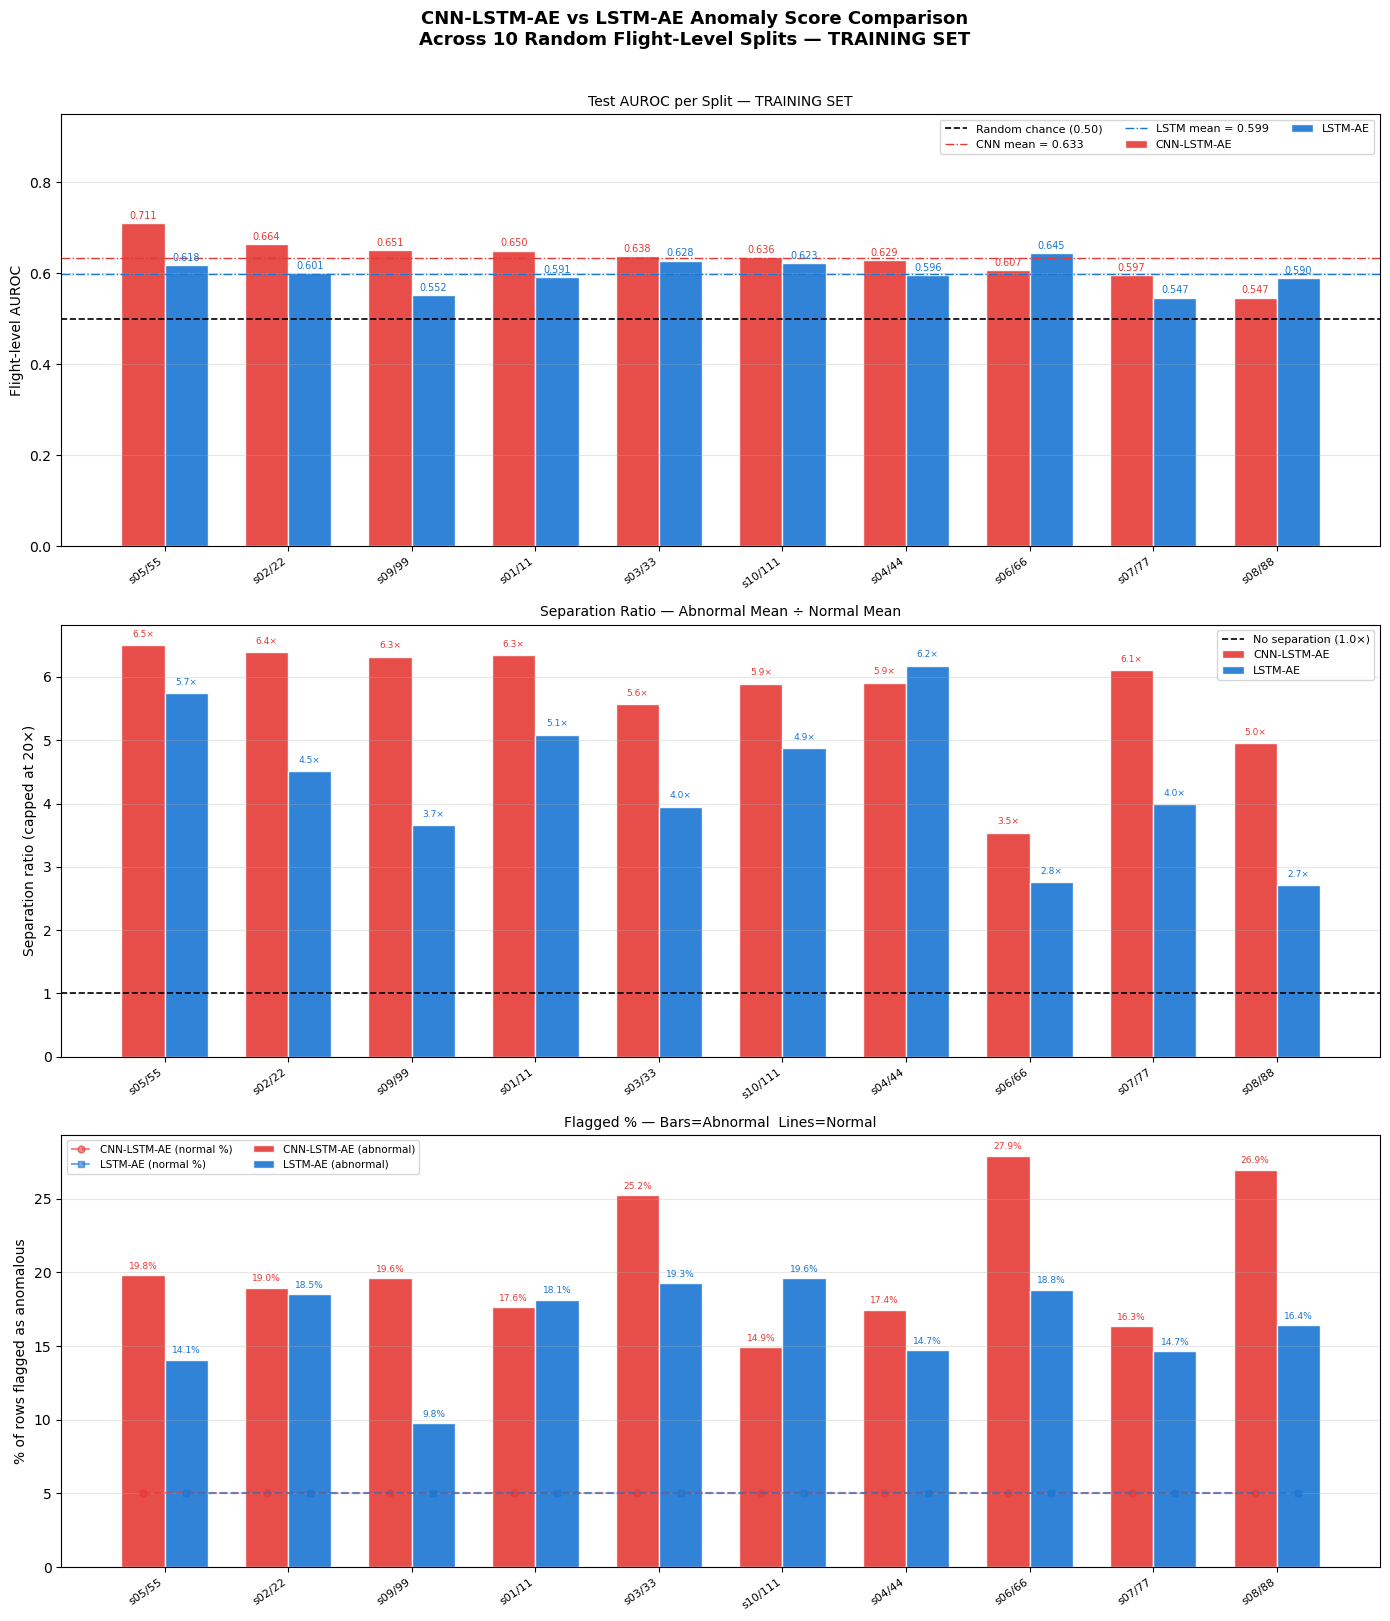

Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/cnn_lstm_ae_anomaly_score_v3_voltage_random10_issue_flight-removed/plots/cnn_vs_lstm_comparison_TRAIN.png

Generating VALIDATION comparison plot...

VALIDATION SET — CNN mean AUROC: 0.6105 vs LSTM: 0.5772  Improvement: +0.0333
CNN wins: 7/10 splits


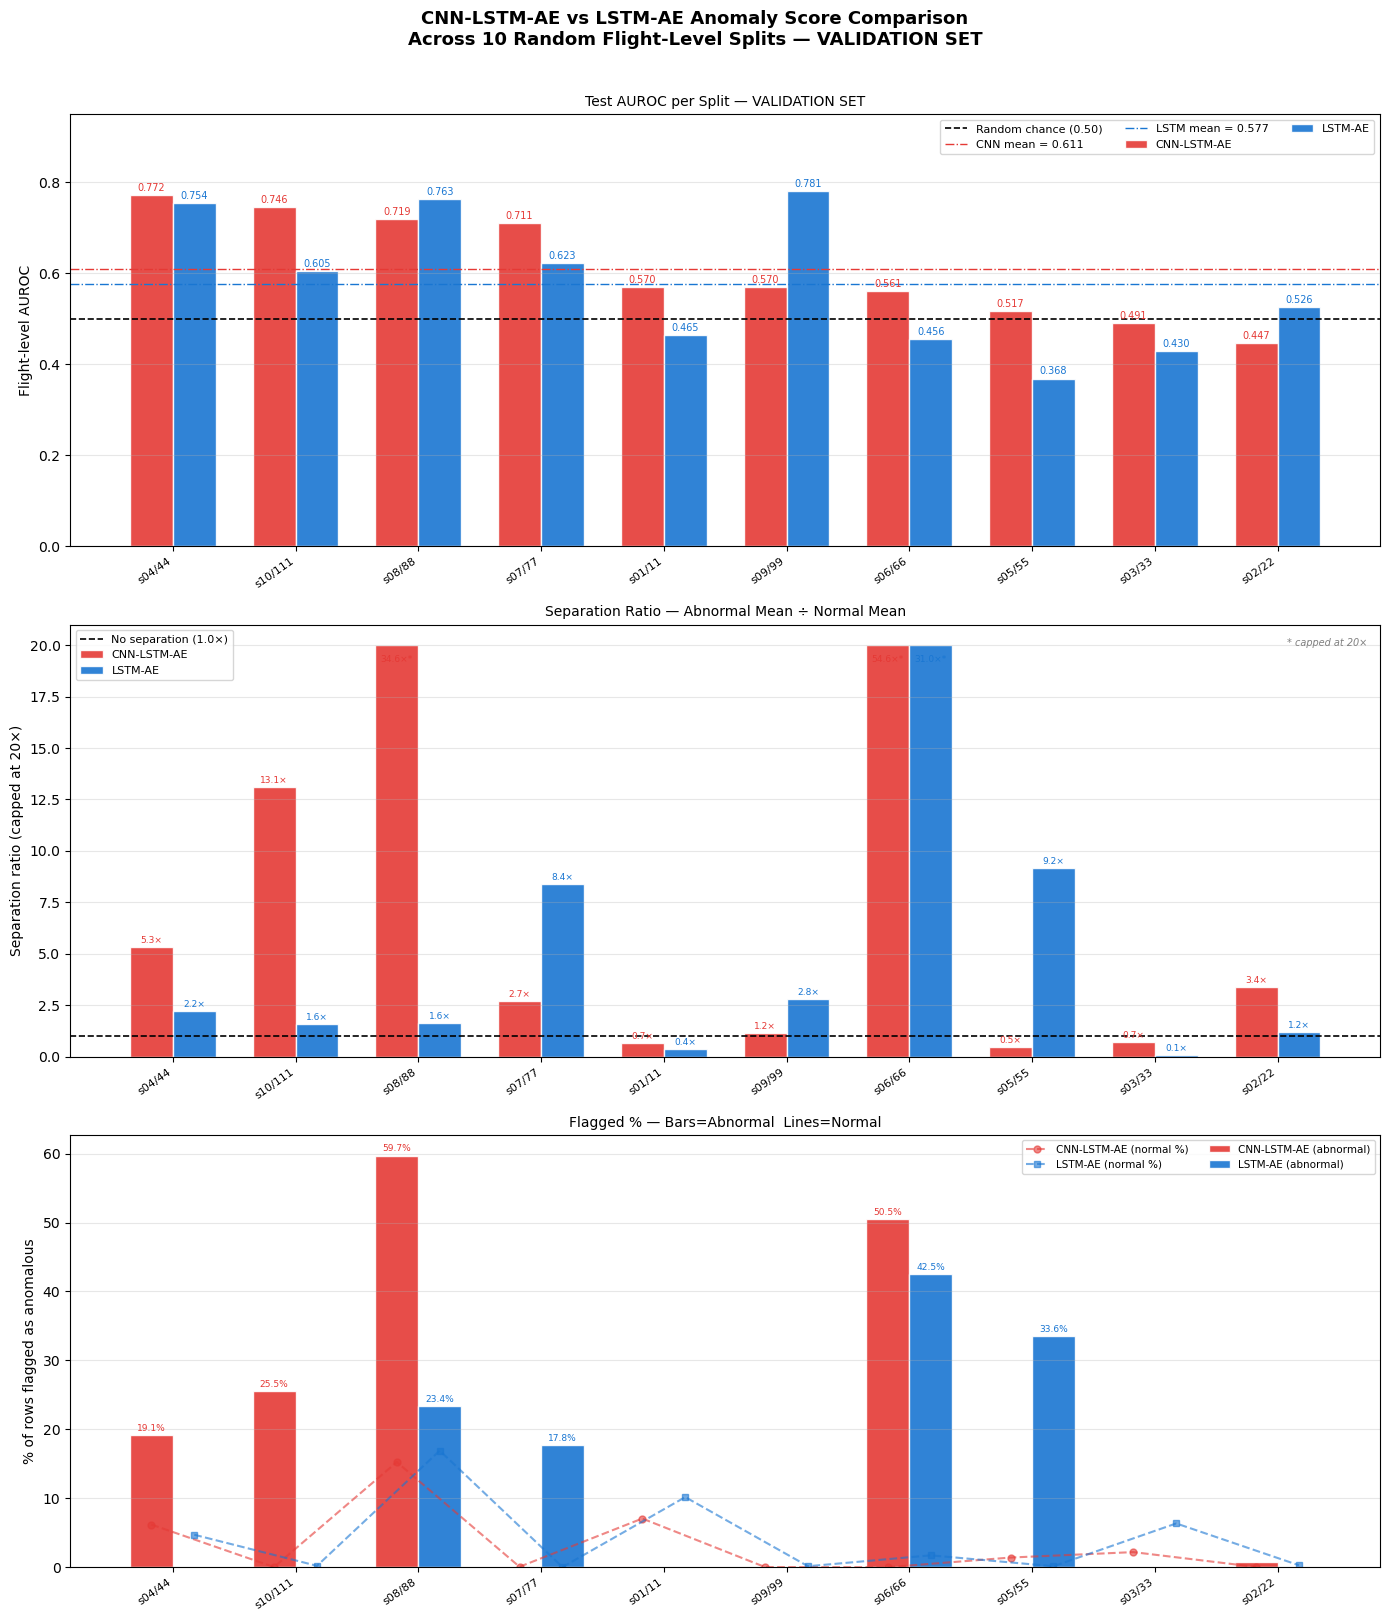

Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/cnn_lstm_ae_anomaly_score_v3_voltage_random10_issue_flight-removed/plots/cnn_vs_lstm_comparison_VAL.png

Generating TEST comparison plot (re-plot for consistency)...

TEST SET — CNN mean AUROC: 0.6376 vs LSTM: 0.5218  Improvement: +0.1158
CNN wins: 10/10 splits


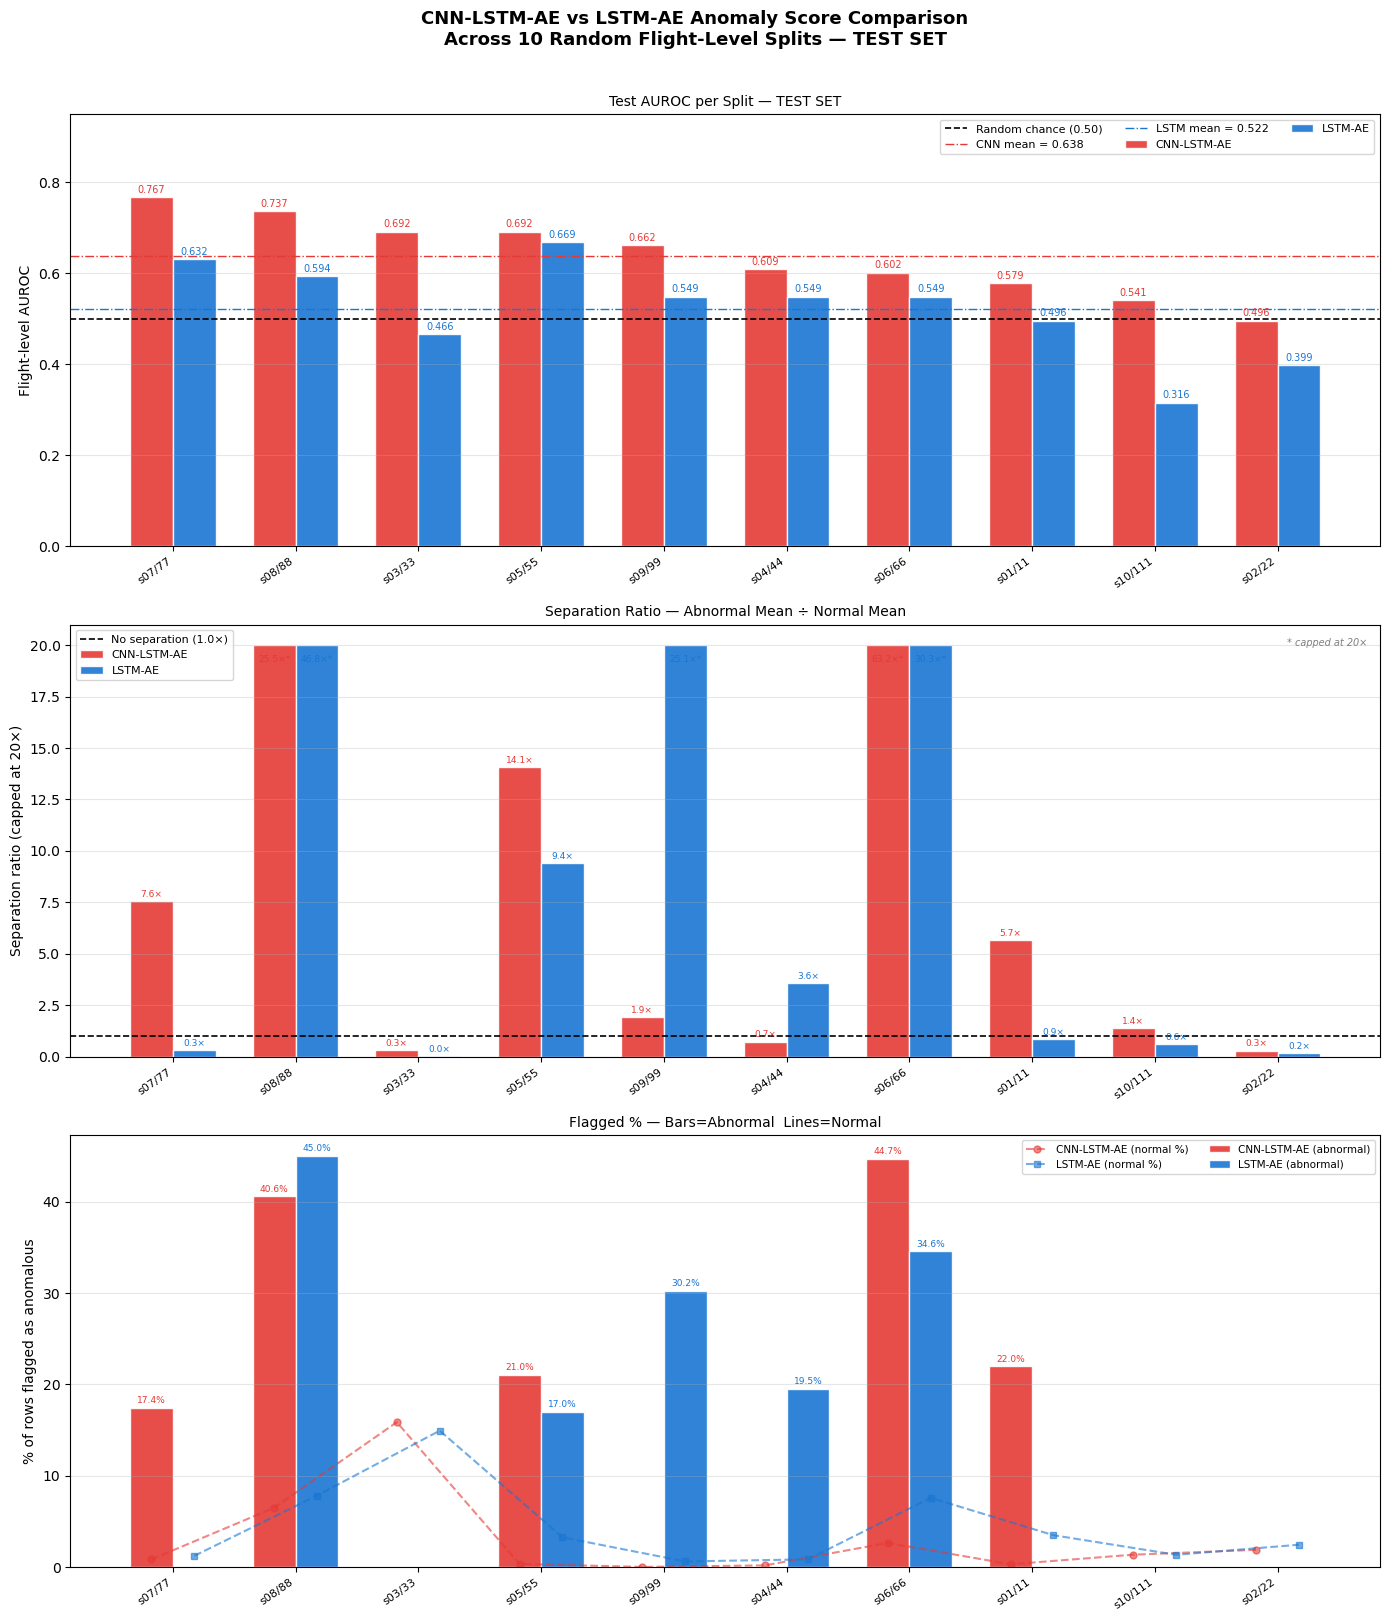

Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/cnn_lstm_ae_anomaly_score_v3_voltage_random10_issue_flight-removed/plots/cnn_vs_lstm_comparison_TEST.png


In [ ]:

# Three-panel comparison plots for TRAIN and VAL

def make_comparison_plot(cnn_df, lstm_df, split_label,
                          save_name, C_CNN="#E53935", C_LSTM="#1976D2"):

    # Merge and sort by CNN AUROC
    cnn_s  = cnn_df[["split","auroc","sep_ratio",
                       "flagged_pct_abn","flagged_pct_nor"]].copy()
    cnn_s.columns = ["split","CNN_auroc","CNN_sep",
                      "CNN_flag_abn","CNN_flag_nor"]
    lstm_s = lstm_df[["split","auroc","sep_ratio",
                        "flagged_pct_abn","flagged_pct_nor"]].copy()
    lstm_s.columns = ["split","LSTM_auroc","LSTM_sep",
                       "LSTM_flag_abn","LSTM_flag_nor"]

    mg = cnn_s.merge(lstm_s, on="split", how="inner")
    mg["improvement"] = (mg["CNN_auroc"] - mg["LSTM_auroc"]).round(4)
    mg = mg.sort_values("CNN_auroc", ascending=False).reset_index(drop=True)

    splits_short = [s.replace("split_","s").replace("_seed_","/")
                    for s in mg["split"]]
    x = np.arange(len(mg))
    w = 0.35

    fig, axes = plt.subplots(3, 1, figsize=(14, 16))
    fig.suptitle(
        f"CNN-LSTM-AE vs LSTM-AE Anomaly Score Comparison\n"
        f"Across 10 Random Flight-Level Splits — {split_label}",
        fontsize=13, fontweight="bold", y=1.01
    )

    # ── Panel 1: AUROC ────────────────────────────────────────
    ax = axes[0]
    b1 = ax.bar(x-w/2, mg["CNN_auroc"],  w, color=C_CNN,
                label="CNN-LSTM-AE", edgecolor="white", alpha=0.9)
    b2 = ax.bar(x+w/2, mg["LSTM_auroc"], w, color=C_LSTM,
                label="LSTM-AE",     edgecolor="white", alpha=0.9)

    for bar, val in zip(b1, mg["CNN_auroc"]):
        ax.text(bar.get_x()+bar.get_width()/2, val+0.005,
                f"{val:.3f}", ha="center", va="bottom",
                fontsize=7, color=C_CNN)
    for bar, val in zip(b2, mg["LSTM_auroc"]):
        ax.text(bar.get_x()+bar.get_width()/2, val+0.005,
                f"{val:.3f}", ha="center", va="bottom",
                fontsize=7, color=C_LSTM)

    ax.axhline(0.5, color="black", linestyle="--", linewidth=1.2,
               label="Random chance (0.50)")
    ax.axhline(mg["CNN_auroc"].mean(), color=C_CNN,
               linestyle="-.", linewidth=1,
               label=f"CNN mean = {mg['CNN_auroc'].mean():.3f}")
    ax.axhline(mg["LSTM_auroc"].mean(), color=C_LSTM,
               linestyle="-.", linewidth=1,
               label=f"LSTM mean = {mg['LSTM_auroc'].mean():.3f}")

    ax.set_xticks(x)
    ax.set_xticklabels(splits_short, rotation=35, ha="right", fontsize=8)
    ax.set_ylabel("Flight-level AUROC", fontsize=10)
    ax.set_title(f"Test AUROC per Split — {split_label}", fontsize=10)
    ax.set_ylim(0, 0.95)
    ax.legend(fontsize=8, ncol=3)
    ax.grid(True, alpha=0.3, axis="y")

    # ── Panel 2: Separation ratio ─────────────────────────────
    ax = axes[1]
    sep_cnn  = [min(v,20) for v in mg["CNN_sep"]]
    sep_lstm = [min(v,20) for v in mg["LSTM_sep"]]
    b3 = ax.bar(x-w/2, sep_cnn,  w, color=C_CNN,
                label="CNN-LSTM-AE", edgecolor="white", alpha=0.9)
    b4 = ax.bar(x+w/2, sep_lstm, w, color=C_LSTM,
                label="LSTM-AE",     edgecolor="white", alpha=0.9)

    for bar, orig in zip(b3, mg["CNN_sep"]):
        label = f"{orig:.1f}×" if orig<=20 else f"{orig:.1f}×*"
        ax.text(bar.get_x()+bar.get_width()/2,
                min(bar.get_height(),19)+0.1,
                label, ha="center", va="bottom",
                fontsize=6.5, color=C_CNN)
    for bar, orig in zip(b4, mg["LSTM_sep"]):
        label = f"{orig:.1f}×" if orig<=20 else f"{orig:.1f}×*"
        ax.text(bar.get_x()+bar.get_width()/2,
                min(bar.get_height(),19)+0.1,
                label, ha="center", va="bottom",
                fontsize=6.5, color=C_LSTM)

    ax.axhline(1.0, color="black", linestyle="--", linewidth=1.2,
               label="No separation (1.0×)")
    ax.set_xticks(x)
    ax.set_xticklabels(splits_short, rotation=35, ha="right", fontsize=8)
    ax.set_ylabel("Separation ratio (capped at 20×)", fontsize=10)
    ax.set_title("Separation Ratio — Abnormal Mean ÷ Normal Mean", fontsize=10)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3, axis="y")
    ax.text(0.99,0.97,"* capped at 20×",transform=ax.transAxes,
            fontsize=7,ha="right",va="top",color="gray",style="italic")

    # ── Panel 3: Flagged % ────────────────────────────────────
    ax = axes[2]
    b5 = ax.bar(x-w/2, mg["CNN_flag_abn"],  w, color=C_CNN,
                label="CNN-LSTM-AE (abnormal)", edgecolor="white", alpha=0.9)
    b6 = ax.bar(x+w/2, mg["LSTM_flag_abn"], w, color=C_LSTM,
                label="LSTM-AE (abnormal)",     edgecolor="white", alpha=0.9)
    ax.plot(x-w/2, mg["CNN_flag_nor"],  "o--", color=C_CNN,
            markersize=5, alpha=0.6, label="CNN-LSTM-AE (normal %)")
    ax.plot(x+w/2, mg["LSTM_flag_nor"], "s--", color=C_LSTM,
            markersize=5, alpha=0.6, label="LSTM-AE (normal %)")

    for bar, val in zip(b5, mg["CNN_flag_abn"]):
        if val > 1:
            ax.text(bar.get_x()+bar.get_width()/2, val+0.3,
                    f"{val:.1f}%", ha="center", va="bottom",
                    fontsize=6.5, color=C_CNN)
    for bar, val in zip(b6, mg["LSTM_flag_abn"]):
        if val > 1:
            ax.text(bar.get_x()+bar.get_width()/2, val+0.3,
                    f"{val:.1f}%", ha="center", va="bottom",
                    fontsize=6.5, color=C_LSTM)

    ax.set_xticks(x)
    ax.set_xticklabels(splits_short, rotation=35, ha="right", fontsize=8)
    ax.set_ylabel("% of rows flagged as anomalous", fontsize=10)
    ax.set_title("Flagged % — Bars=Abnormal  Lines=Normal", fontsize=10)
    ax.legend(fontsize=7.5, ncol=2)
    ax.grid(True, alpha=0.3, axis="y")

    # Print summary
    print(f"\n{split_label} — CNN mean AUROC: {mg['CNN_auroc'].mean():.4f} "
          f"vs LSTM: {mg['LSTM_auroc'].mean():.4f}  "
          f"Improvement: {mg['improvement'].mean():+.4f}")
    print(f"CNN wins: {(mg['improvement']>0).sum()}/{len(mg)} splits")

    plt.tight_layout()
    save_path = PLOT_DIR / save_name
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved: {save_path}")
    return mg


# Generate all three plots
print("Generating TRAIN comparison plot...")
train_mg = make_comparison_plot(
    tr_cnn, tr_lstm,
    split_label="TRAINING SET",
    save_name="cnn_vs_lstm_comparison_TRAIN.png"
)

print("\nGenerating VALIDATION comparison plot...")
val_mg = make_comparison_plot(
    vl_cnn, vl_lstm,
    split_label="VALIDATION SET",
    save_name="cnn_vs_lstm_comparison_VAL.png"
)

print("\nGenerating TEST comparison plot (re-plot for consistency)...")
# Reload test results from the already computed merged DataFrame
test_mg = make_comparison_plot(
    cnn_df.rename(columns={"auroc":"auroc","sep_ratio":"sep_ratio",
                            "flagged_pct_abn":"flagged_pct_abn",
                            "flagged_pct_nor":"flagged_pct_nor"}),
    lstm_df_summary,
    split_label="TEST SET",
    save_name="cnn_vs_lstm_comparison_TEST.png"
)